In [1]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer

from src.alentar_llm.metrics import (calculate_mmd, show_embeddings,
                                     get_top_ngrams, get_meteor, get_rouge,
                                     calculate_all_sms, calculate_self_bleu,
                                     lexical_diversity, calculate_nnd,
                                     get_plagiarism_candidates,
                                     get_bertscore)

/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


# Load data (real and synthetic)

In [2]:
df_da = pd.read_csv('llm_responses_deepseek-r1.csv', delimiter='|')
da_reports = df_da['response'].values
df_da.head(2)

,model,code,response,prompt,response_raw,time
0,deepseek-r1:7b_es,[F30.9],Episodio maníaco de inicio repentino sin causa...,A continuación tienes información sobre una et...,"```json\n{\n ""caso 1"": {\n ""[F30.9]"": ""Epi...",76.02
1,deepseek-r1:7b_es,[F30.9],Manía con reducción significativa de la necesi...,A continuación tienes información sobre una et...,"```json\n{\n ""caso 1"": {\n ""[F30.9]"": ""Epi...",76.02


In [3]:
df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')
df_real.head(2)

/tmp/ipykernel_2438756/1343324431.py:1: DtypeWarning: Columns (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93) have mixed types. Specify dtype option on import or set low_memory=False.
  df_real = pd.read_csv('Informes-Urgencias/EJEI_nocod_Clasificator_2024_07_ 04. 4.fin.csv')


,EJEIDiagnóstico,REVISADO,altas_capacidades,No_DX,F30.9,F31.0,F31.1,F31.3,F31.81,F31.9,...,F13,F14,F17,F19,F20,F21,F22,F25,F29,F32.3
0,F30.2 - MANÍA CON SÍNTOMAS PSICÓTICOS.,1,,,1,,,,,,...,,,,,,,,,,
1,\r\nDescompensación rasgos patológicos de pers...,1,,,,,,,,,...,,,,,,,,,,


In [4]:
# Reduce real data to accelerate the process
# df_real = df_real.sample(frac=0.1, random_state=42)
real_reports = df_real['EJEIDiagnóstico'].values

In [5]:
df_results = pd.DataFrame()

## Evaluate DA

In [6]:
model = SentenceTransformer('all-MiniLM-L6-v2')
emb_real = model.encode(real_reports)
emb_da = model.encode(da_reports)

ERROR! Session/line number was not unique in database. History logging moved to new session 455


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6990.17it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [7]:
df_results.at['deepseek-r1', 'MMD'] = calculate_mmd(emb_real, emb_da)
for key, value in get_rouge(real_reports, da_reports).items():
    df_results.at['deepseek-r1', key] = value
df_results.at['deepseek-r1', 'METEOR'] = get_meteor(real_reports, da_reports)['meteor']
df_results.at['deepseek-r1', 'Average_SMS'] = np.mean(calculate_all_sms(real_reports, da_reports))
df_results.at['deepseek-r1', 'Self_BLEU'] = calculate_self_bleu(da_reports)
df_results.at['deepseek-r1', 'TTR'] = lexical_diversity(da_reports)
df_results.at['deepseek-r1', 'Average_NND'], all_nnds = calculate_nnd(emb_real, emb_da)
P, R, F1 = get_bertscore(real_reports, da_reports)
df_results.at['deepseek-r1', 'Average_BERTScore_F1'] = F1.mean().item()

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
/workspace/Alentar_LLM/src/alentar_llm/metrics.py:97: UserWarning: [W008] Evaluating Doc.similarity based on empty vectors.
  return doc1.similarity(doc2)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3749.54it/s]
BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  |

In [8]:
df_results

,MMD,rouge1,rouge2,rougeL,rougeLsum,METEOR,Average_SMS,Self_BLEU,TTR,Average_NND,Average_BERTScore_F1
deepseek-r1,0.019661,0.064733,0.005055,0.060444,0.061104,0.049577,0.46453,0.141294,0.985915,0.16266,0.690621


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 146252 samples in 0.028s...
[t-SNE] Computed neighbors for 146252 samples in 94.840s...
[t-SNE] Computed conditional probabilities for sample 1000 / 146252
[t-SNE] Computed conditional probabilities for sample 2000 / 146252
[t-SNE] Computed conditional probabilities for sample 3000 / 146252
[t-SNE] Computed conditional probabilities for sample 4000 / 146252
[t-SNE] Computed conditional probabilities for sample 5000 / 146252
[t-SNE] Computed conditional probabilities for sample 6000 / 146252
[t-SNE] Computed conditional probabilities for sample 7000 / 146252
[t-SNE] Computed conditional probabilities for sample 8000 / 146252
[t-SNE] Computed conditional probabilities for sample 9000 / 146252
[t-SNE] Computed conditional probabilities for sample 10000 / 146252
[t-SNE] Computed conditional probabilities for sample 11000 / 146252
[t-SNE] Computed conditional probabilities for sample 12000 / 146252
[t-SNE] Computed conditional probab

[t-SNE] Computed conditional probabilities for sample 123000 / 146252
[t-SNE] Computed conditional probabilities for sample 124000 / 146252
[t-SNE] Computed conditional probabilities for sample 125000 / 146252
[t-SNE] Computed conditional probabilities for sample 126000 / 146252
[t-SNE] Computed conditional probabilities for sample 127000 / 146252
[t-SNE] Computed conditional probabilities for sample 128000 / 146252
[t-SNE] Computed conditional probabilities for sample 129000 / 146252
[t-SNE] Computed conditional probabilities for sample 130000 / 146252
[t-SNE] Computed conditional probabilities for sample 131000 / 146252
[t-SNE] Computed conditional probabilities for sample 132000 / 146252
[t-SNE] Computed conditional probabilities for sample 133000 / 146252
[t-SNE] Computed conditional probabilities for sample 134000 / 146252
[t-SNE] Computed conditional probabilities for sample 135000 / 146252
[t-SNE] Computed conditional probabilities for sample 136000 / 146252
[t-SNE] Computed con

/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Wed Mar 11 10:18:45 2026 Finding Nearest Neighbors
Wed Mar 11 10:18:45 2026 Building RP forest with 24 trees
Wed Mar 11 10:19:03 2026 NN descent for 17 iterations
	 1  /  17
	 2  /  17
	 3  /  17
	 4  /  17
	Stopping threshold met -- exiting after 4 iterations
Wed Mar 11 10:19:44 2026 Finished Nearest Neighbor Search
Wed Mar 11 10:19:48 2026 Construct embedding


/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/micromamba/envs/alentar_llm_env/lib/python3.12/site-packages/umap/s

...

	completed  160  /  200 epochs


Epochs completed:  90%| █████████  181/200 [04:03]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [04:29]


Wed Mar 11 10:38:06 2026 Finished embedding


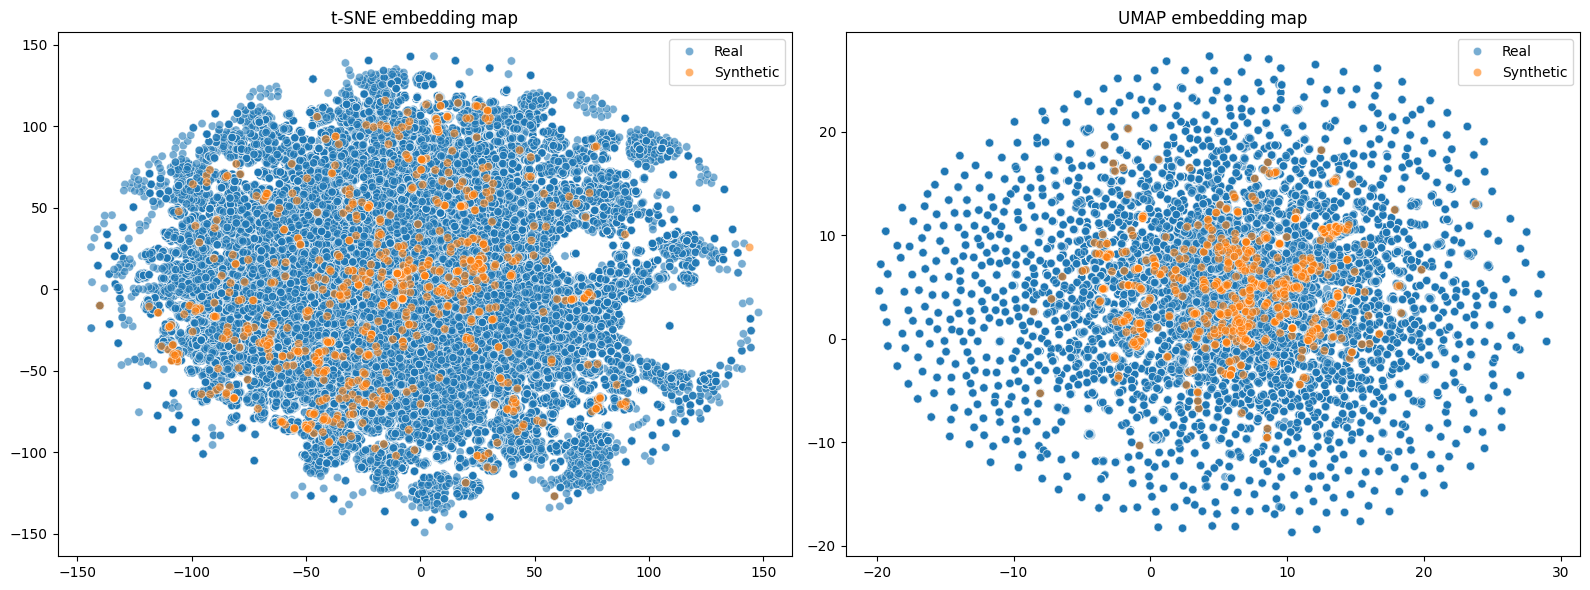

In [11]:
show_embeddings(emb_real, emb_da)

In [12]:
n = 2
top_real = get_top_ngrams(real_reports, n=n)
top_da = get_top_ngrams(da_reports, n=n)

print(f"Top Real {n}-grams:", top_real)
print(f"\nTop Synthetic {n}-grams:", top_da)

Top Real 2-grams: [('trastorno de', np.int64(9179)), ('de ansiedad', np.int64(6449)), ('deterioro cognitivo', np.int64(6046)), ('de personalidad', np.int64(5563)), ('trastorno adaptativo', np.int64(5415)), ('en remisión', np.int64(4941)), ('impresiona de', np.int64(4721)), ('trastorno depresivo', np.int64(4683)), ('de inicio', np.int64(4133)), ('de deterioro', np.int64(4088))]

Top Synthetic 2-grams: [('trastorno de', np.int64(66)), ('trastorno bipolar', np.int64(36)), ('de ansiedad', np.int64(31)), ('en paciente', np.int64(30)), ('con síntomas', np.int64(30)), ('episodio depresivo', np.int64(30)), ('de la', np.int64(29)), ('ansiedad generalizada', np.int64(27)), ('de personalidad', np.int64(27)), ('paciente con', np.int64(24))]


In [13]:
plagiarism_threshold = 0.05 
leaked = np.sum(all_nnds < plagiarism_threshold)
print(f"Reports with suspicion of plagiarism (<{plagiarism_threshold} dist): {leaked}")

df_suspicius = get_plagiarism_candidates(
    da_reports, 
    real_reports, 
    emb_da, 
    emb_real, 
    threshold=plagiarism_threshold
)

df_suspicius

Reports with suspicion of plagiarism (<0.05 dist): 67


,Synthetic_ID,NND,Synthetic report,Closest neighbor
12,140,0.0000,Ansiedad generalizada,ansiedad generalizada
13,142,0.0000,Fobia social,Fobia social
14,144,0.0000,Fobia específica a las alturas,Fobia específica a las alturas
11,139,0.0000,Trastorno de pánico,Trastorno de pánico
20,192,0.0000,Trastorno ansioso-depresivo no especificado,Trastorno ansioso-depresivo no especificado
...,...,...,...,...
43,452,0.0468,Personalidad con rasgos obsesivo-compulsivos y...,Personalidad con rasgos obsesivos y evitativos.
61,702,0.0474,Trastorno por ideas delirantes no especificado,Trastorno por ideas delirantes
6,75,0.0482,Episodio depresivo en contexto de duelo compli...,Episodio depresivo en contexto de duelo.
5,42,0.0482,Cuadro depresivo actual sin síntomas psicótico...,Trastorno bipolar. Fase depresiva actual sin ...
